
# Drone Delivery Optimization using QAOA

This tutorial demonstrates how to apply **Quantum Approximate Optimization Algorithm (QAOA)** to a 
**drone delivery optimization problem**, which can be modeled as a variant of the 
**Traveling Salesman Problem (TSP)**.

We will walk through the following:

1. **Introduction**
2. **Background Concepts**
   - The Drone Delivery Problem
   - Mapping to TSP and QUBO
   - Quantum Optimization with QAOA
3. **Implementation in Qiskit**
   - Problem Setup
   - Building the Cost Hamiltonian
   - Applying QAOA
   - Evaluating Results
4. **Analysis & Visualization**
5. **Conclusions and Next Steps**

---



## 1. Introduction

Drone delivery services are becoming increasingly relevant in logistics and transportation. 
The main challenge lies in optimizing routes to minimize distance, time, or energy consumption, 
while adhering to operational constraints.

This tutorial shows how we can use **quantum algorithms** to approach such optimization problems, 
with a focus on QAOA in Qiskit.



## 2. Background Concepts

### 2.1 The Drone Delivery Problem
The core task is to determine the optimal route for drones to deliver packages efficiently. 
This is closely related to the **Traveling Salesman Problem (TSP)**.

### 2.2 Mapping to TSP and QUBO
- **TSP**: Visit all required nodes (delivery locations) exactly once with minimum cost.
- **QUBO (Quadratic Unconstrained Binary Optimization)**: Encode constraints and cost function into a binary quadratic form.

By representing drone delivery as a TSP instance, we can transform it into a **QUBO problem**.

### 2.3 Quantum Optimization with QAOA
QAOA is a **hybrid quantum-classical algorithm** for solving combinatorial optimization problems.
- Uses a **cost Hamiltonian** encoding the optimization objective.
- Alternates between cost and mixing operators.
- Parameters are optimized with a classical optimizer.

This makes QAOA well-suited for problems like drone routing.




### 2.4 Mathematical Formulation (TSP → QUBO → Ising)

#### Notation

* Let the delivery locations (including depot if used) be

  $$
  V = \{0,1,\dots,n-1\}.
  $$
* We use a **position-based** (one-hot) encoding with binary variables

  $$
  x_{i,t} \in \{0,1\} \quad \text{meaning "city \(i\) is visited at tour position \(t\)"},
  $$

  for $i \in V$ and $t \in \{0,1,\dots,n-1\}$.
* Let $d_{ij} \ge 0$ denote the distance/energy/time cost from city $i$ to $j$.
  Define

  $$
  t \oplus 1 := (t+1)\bmod n
  $$

  for cyclic tours.

---

#### Objective (tour length / energy)

$$
C_{\text{dist}}(x) = \sum_{t=0}^{n-1} \sum_{i=0}^{n-1} \sum_{j=0}^{n-1} d_{ij}\, x_{i,t}\, x_{j,t \oplus 1}.
$$

---

#### Constraints (one-hot feasibility)

1. **Each city is visited exactly once**

   $$
   \sum_{t=0}^{n-1} x_{i,t} = 1 \quad \forall i \in V.
   $$

2. **Exactly one city is chosen at each tour position**

   $$
   \sum_{i=0}^{n-1} x_{i,t} = 1 \quad \forall t \in \{0,\dots,n-1\}.
   $$

(If a fixed depot at city $0$ is required, enforce $x_{0,0} = 1$ and remove its column/row accordingly.)

---

#### QUBO construction

We convert equality constraints into quadratic penalties with positive weights $A$ (constraints) and $B$ (objective scale):

$$
H_{\text{visit}}(x) = A \sum_{i=0}^{n-1}\left(1 - \sum_{t=0}^{n-1} x_{i,t}\right)^2,
$$

$$
H_{\text{pos}}(x) = A \sum_{t=0}^{n-1}\left(1 - \sum_{i=0}^{n-1} x_{i,t}\right)^2,
$$

$$
H_{\text{obj}}(x) = B \sum_{t=0}^{n-1} \sum_{i=0}^{n-1} \sum_{j=0}^{n-1} d_{ij}\, x_{i,t}\, x_{j,t \oplus 1}.
$$

The full QUBO objective is:

$$
H_{\text{QUBO}}(x) = H_{\text{visit}}(x) + H_{\text{pos}}(x) + H_{\text{obj}}(x).
$$

**Penalty choice.**
A practical rule:

$$
A \gtrsim n \cdot \max_{i,j} d_{ij}
$$

so that feasibility is prioritized over distance minimization.

---

#### Ising mapping (binary $\rightarrow$ Pauli-$Z$)

Binary variables map to spins via:

$$
x = \frac{1 - Z}{2} \quad \Rightarrow \quad 
x_a x_b = \tfrac{1}{4}\left(1 - Z_a - Z_b + Z_a Z_b\right).
$$

Replacing every $x_{i,t}$ with $(1 - Z_{i,t})/2$ yields a Hamiltonian of the form:

$$
H_C = \sum_{q} h_q Z_q + \sum_{q<r} J_{qr} Z_q Z_r + \text{const},
$$

acting on $n^2$ qubits (one per $x_{i,t}$).

---




## 3. Implementation in Qiskit

In this section, we implement the drone delivery optimization using Qiskit.
We will follow these steps:

1. Define the delivery graph (nodes = delivery points, edges = costs/distances).
2. Encode the optimization as a QUBO problem.
3. Construct the cost Hamiltonian in Qiskit.
4. Solve using QAOA with a classical optimizer.



### 3.1 Problem Setup

We start by defining the delivery graph, representing drone delivery locations and travel costs.



### 3.2.1 From QUBO to Pauli-$Z$ Hamiltonian

Start with a quadratic polynomial in binary variables:

$$
H_{\text{QUBO}}(x) \;=\; \sum_k a_k x_k \;+\; \sum_{k<\ell} b_{k\ell}\, x_k x_\ell \;+\; c.
$$

Using the mapping

$$
x_k = \frac{1 - Z_k}{2},
$$

we substitute and regroup terms. The resulting Hamiltonian takes the form

$$
H_C \;=\;
\underbrace{\left(c + \tfrac{1}{2}\sum_k a_k + \tfrac{1}{4}\sum_{k<\ell} b_{k\ell}\right)}_{\text{const}}
+ \sum_k \underbrace{\left(-\tfrac{1}{2}a_k - \tfrac{1}{4}\sum_{\ell\neq k} b_{k\ell}\right)}_{h_k}\, Z_k
+ \sum_{k<\ell} \underbrace{\tfrac{1}{4} b_{k\ell}}_{J_{k\ell}} \, Z_k Z_\ell.
$$

---

* The **constant term** only shifts the energy spectrum and is irrelevant for QAOA evolution.
* The **linear terms** give local fields $h_k$ on each qubit.
* The **quadratic terms** give couplings $J_{k\ell}$ between qubits.

Thus the QUBO is mapped to an Ising Hamiltonian suitable for QAOA’s cost unitary:

$$
H_C = \sum_k h_k Z_k + \sum_{k<\ell} J_{k\ell} Z_k Z_\ell + \text{const}.
$$

---




### 3.3.1 QAOA Ansatz and Mixers

Let $H_C$ be the Ising cost Hamiltonian, and choose a mixer Hamiltonian $H_B$.

* **Standard mixer (unconstrained one-hot):**

  $$
  H_B \;=\; \sum_q X_q.
  $$

* **One-hot preserving XY mixer (optional):**

  $$
  H_B^{(\text{XY})} \;=\; \sum_{\substack{\text{within each}\\ \text{one-hot block}}} 
  \bigl(X_u X_v + Y_u Y_v \bigr),
  $$

  which preserves Hamming weight within blocks (useful when strictly enforcing one-hot constraints).

---

For QAOA depth $p$ and parameters $(\boldsymbol\gamma,\boldsymbol\beta)\in \mathbb{R}^p \times \mathbb{R}^p$:

$$
\begin{aligned}
U_C(\gamma) &= e^{-i\gamma H_C}, 
&\quad U_B(\beta) &= e^{-i\beta H_B}, \\[6pt]
\lvert \boldsymbol\gamma, \boldsymbol\beta \rangle 
&= U_B(\beta_p)\, U_C(\gamma_p)\, \cdots \, U_B(\beta_1)\, U_C(\gamma_1)\, \lvert + \rangle^{\otimes n^2}.
\end{aligned}
$$

---

The variational objective is:

$$
E(\boldsymbol\gamma, \boldsymbol\beta) \;=\; 
\langle \boldsymbol\gamma, \boldsymbol\beta \,\vert\, H_C \,\vert\, \boldsymbol\gamma, \boldsymbol\beta \rangle.
$$

A classical optimizer searches over parameters $(\boldsymbol\gamma, \boldsymbol\beta)$ to minimize $E$.

---



### 3.4.1 Decoding, Feasibility & Tour Cost

After measurement, a bitstring

$$
z \in \{0,1\}^{n^2}
$$

is reshaped into an $n \times n$ assignment matrix

$$
X = [x_{i,t}],
$$

where $x_{i,t}$ indicates whether city $i$ is visited at position $t$.

---

#### Validity Check

* **Valid one-hot assignment:**
  Each **row** (city) and each **column** (position) must sum to $1$.
  A valid assignment corresponds to a permutation matrix, from which the tour $\pi$ is extracted by reading the unique city at each position $t$.
* **Invalid assignment:**

  * **Repair:** project each row/column to a valid one-hot encoding (heuristic correction).
  * **Discard:** drop infeasible samples (if strict feasibility is required).

---

#### Tour Cost

For a valid permutation $\pi$, the cyclic tour cost is

$$
\text{cost}(\pi) = \sum_{t=0}^{n-1} d_{\pi(t),\, \pi(t \oplus 1)},
$$

where $t \oplus 1 := (t+1) \bmod n$.

---

#### Quality Metrics

* **Feasibility rate:** fraction of measured samples that yield valid one-hot solutions.
* **Best / mean cost:** evaluate the minimum and average cost among feasible tours.
* **Approximation ratio:**

  $$
  \frac{\min_{\text{samples}} \text{cost}(\pi)}{\text{OPT}},
  $$

  if the true optimum cost (OPT) is known.





### 4.1 Penalty Scaling & Practical Tips

* **Penalty weight selection:**
  A good starting rule is

  $$
  A \;\in\; \bigl[n \cdot d_{\max}, \; 5n \cdot d_{\max}\bigr],
  \qquad 
  B = 1,
  $$

  where

  $$
  d_{\max} = \max_{i,j} d_{ij}.
  $$

* **Balancing feasibility vs. optimization:**

  * If many **infeasible samples** are observed → **increase $A$** so constraints dominate.
  * If nearly all samples are feasible but routes are suboptimal → increase **QAOA depth $p$** or improve the classical optimizer.

* **Scaling to larger $n$:**

  * **Warm-starts:** initialize QAOA parameters from smaller problem instances or classical heuristics.
  * **Problem symmetries:** fix a reference city (e.g., depot at position $0$) to reduce redundancy.
  * **Coarse-to-fine graphs:** solve on a reduced graph (clustering cities) and refine on the full graph.

---



### 3.2 Building the QUBO and Hamiltonian

Next, we encode the problem as a QUBO and map it to a Hamiltonian suitable for QAOA.



### 3.3 Applying QAOA

We configure QAOA in Qiskit, setting parameters like number of layers (`p`) and optimizer type.



### 3.4 Evaluating Results

After running QAOA, we interpret the measurement results, extracting the optimal route for the drone.



## 4. Analysis & Visualization

We analyze the obtained solutions and visualize the optimized delivery route.

- Compare classical vs quantum solutions.
- Visualize the best found route.
- Discuss scalability challenges and possible improvements.



## 5. Conclusions and Next Steps

- QAOA can provide approximate solutions to complex routing problems such as drone delivery.
- Hybrid quantum-classical workflows allow experimentation today, even with small quantum devices.
- Future work may involve:
  - Scaling to larger drone fleets and delivery networks.
  - Exploring alternative quantum optimization algorithms (e.g., VQE, QAOA with warm-starts).
  - Integration with real-world logistics datasets.

---




In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from qiskit_optimization.applications import Tsp
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA, SPSA, ADAM
from qiskit.primitives import Sampler
from qiskit_optimization import QuadraticProgram
import random
import time

In [3]:
def draw_graph(G, path=None):
    pos = nx.spring_layout(G)
    edge_labels = nx.get_edge_attributes(G, 'weight')
    colors = ['red' if node in path else 'lightblue' for node in G.nodes()] if path else 'lightblue'

    nx.draw_networkx(G, pos, node_color=colors, with_labels=True)
    nx.draw_networkx_edge_labels(G, pos, edge_labels)

    if path:
        edge_path = [(path[i], path[(i+1)%len(path)]) for i in range(len(path))]
        nx.draw_networkx_edges(G, pos, edgelist=edge_path, edge_color='blue', width=2)
        
    plt.show()

In [ ]:
def tsp_solver(tsp_custom, qp ):
    sampler = Sampler()
    qaoa = QAOA(sampler=sampler, optimizer=COBYLA(), reps=1)

    qaoa_optimizer = MinimumEigenOptimizer(qaoa)

    quantum_result = qaoa_optimizer.solve(qp)
    quantum_path = tsp_custom.interpret(quantum_result.x)

    return quantum_result.fval, quantum_path      

In [5]:
def tsp_solver_qubo(tsp_custom, qp):
    sampler = Sampler()
    qaoa_cost_history = []

    def callback_fn(eval_count, params, mean, norm, accepted):
        qaoa_cost_history.append(mean)
        print(f"Step {eval_count}, Cost: {mean}, Norm: {norm}, Accepted: {accepted}")

    qubo = QuadraticProgramToQubo()
    qubo_converter = qubo.convert(qp)

    qaoa = QAOA(sampler=sampler, optimizer=SPSA(maxiter = 100, callback = callback_fn))

    qaoa_optimizer = MinimumEigenOptimizer(qaoa)

    quantum_result = qaoa_optimizer.solve(qubo_converter)    
    quantum_path = tsp_custom.interpret(quantum_result.x)

    return quantum_result.fval, quantum_path, qaoa_cost_history        

In [6]:
def route_cost(path, dist_matrix):
    return sum(dist_matrix[path[i]][path[(i+1)%len(path)]] for i in range(len(path)))

In [8]:
def simulated_annealing(dist_matrix, temp=10000.0, cooling_rate=0.995, stopping_temp=1e-8, initial_solution=None):
    num_nodes = len(dist_matrix)
    if initial_solution is None:
        curr_solution = list(range(num_nodes))
    else:
        curr_solution = initial_solution[:]
    best_solution = curr_solution[:]
    best_cost = route_cost(curr_solution, dist_matrix)
    cost_history = [best_cost]

    while temp > stopping_temp:
        new_solution = curr_solution[:]
        i, j = random.sample(range(num_nodes), 2)
        new_solution[i], new_solution[j] = new_solution[j], new_solution[i]
        new_cost = route_cost(new_solution, dist_matrix)
        
        if new_cost < best_cost or random.random() < np.exp((best_cost - new_cost) / temp):
            curr_solution = new_solution[:]
            if new_cost < best_cost:
                best_solution = new_solution[:]
                best_cost = new_cost
                cost_history.append(best_cost)
                
        temp *= cooling_rate

    return best_solution, best_cost, cost_history

In [ ]:
def hybrid_solver(tsp_custom, qp, dist_matrix, iterations=3):
    
    best_path, best_cost, sa_history = simulated_annealing(dist_matrix)
    print("Initial candidate from Simulated Annealing:")
    print("Path:", best_path, "Cost:", best_cost)
    hybrid_history = [best_cost]
    
    for it in range(iterations):
        print(f"\nHybrid Iteration {it+1}:")
    
        obj_quantum, q_path = tsp_solver(tsp_custom, qp)
        print("Quantum candidate (QAOA):")
        print("Path:", q_path, "Cost:", obj_quantum)
    
        if obj_quantum < best_cost:
            best_cost = obj_quantum
            best_path = q_path[:]
        
        new_path, new_cost, _ = simulated_annealing(dist_matrix, initial_solution=best_path)
        print("Refined candidate (Simulated Annealing):")
        print("Path:", new_path, "Cost:", new_cost)
        if new_cost < best_cost:
            best_cost = new_cost
            best_path = new_path[:]
        hybrid_history.append(best_cost)
    
    return best_path, best_cost, hybrid_history

## 4 nodes

In [9]:
custom_matrix = np.array([
    [0, 2, 9, 10],
    [2, 0, 7, 4],
    [9, 7, 0, 8],
    [10, 4, 8, 0]
])

n_nodes = custom_matrix.shape[0]

In [10]:
G_custom = nx.complete_graph(n_nodes)


In [11]:
for i, j in G_custom.edges():
    G_custom[i][j]['weight'] = custom_matrix[i][j]

In [12]:
tsp_custom = Tsp(G_custom)

In [13]:
graph = tsp_custom.graph

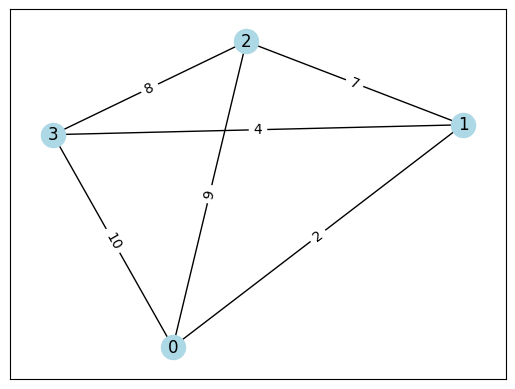

In [14]:
draw_graph(graph)


In [18]:
qp = tsp_custom.to_quadratic_program()

In [41]:
qaoa = QAOA(sampler=Sampler(), optimizer=COBYLA(), reps=1)

qp_solver = MinimumEigenOptimizer(qaoa)
qp_result = qp_solver.solve(qp)

qc = qaoa.ansatz

In [ ]:
qaoa_start = time.time()
obj, path = tsp_solver(tsp_custom, qp)
qaoa_end = time.time()

print(f"QAOA Time: {qaoa_end - qaoa_start:.4f} seconds")
print(f"QAOA Solution: {path}\n Cost: {obj}")

QAOA Time: 226.9048 seconds
QAOA Solution: [3, 2, 0, 1]
 Cost: 23.0


Step 3, Cost: 233.69319871599944, Norm: 0.40615579259358464, Accepted: True
Step 6, Cost: 387.8722134435071, Norm: 0.25750379926371914, Accepted: True
Step 9, Cost: 21.371028175799054, Norm: 1.0138010246048812, Accepted: True
Step 12, Cost: 709.845351607552, Norm: 18.85753800622198, Accepted: True
Step 15, Cost: 41.7982874295244, Norm: 0.7821040400491325, Accepted: True
Step 18, Cost: -9.749997408160622, Norm: 0.2848910221102469, Accepted: True
Step 21, Cost: -128.08642759101963, Norm: 0.11961816211336343, Accepted: True
Step 24, Cost: 621.927217708531, Norm: 0.5152547384498085, Accepted: True
Step 27, Cost: -3.9079156974980656, Norm: 2.694389514511236, Accepted: True
Step 30, Cost: -1.1336349880223875, Norm: 0.15001479634639184, Accepted: True
Step 33, Cost: 0.012608197061227233, Norm: 0.25672104833015114, Accepted: True
Step 36, Cost: 78.16879371537249, Norm: 0.25953612944818466, Accepted: True
Step 39, Cost: -1.1251173537809747, Norm: 0.01528202206791592, Accepted: True
Step 42, Cos

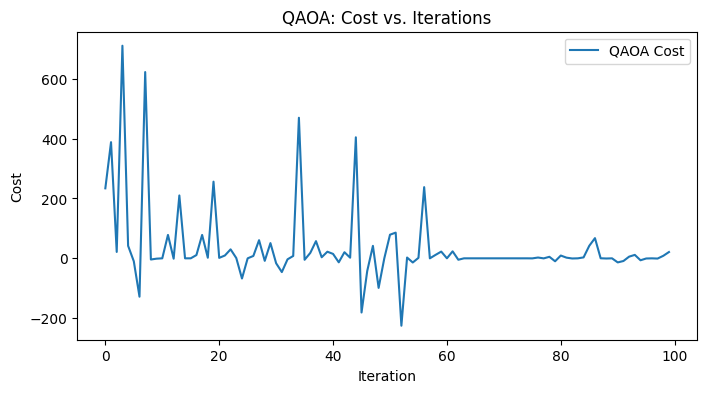

In [54]:
qaoa_qubo_start = time.time()
obj_qubo, path_qubo, qaoa_cost_history = tsp_solver_qubo(tsp_custom, qp)
qaoa_qubo_end = time.time()

print(f"QAOA QUBO Time: {qaoa_qubo_end - qaoa_qubo_start:.4f} seconds")
print(f"QAOA Solution: {path_qubo}\n Cost: {obj_qubo}")

plt.figure(figsize=(8, 4))
plt.plot(qaoa_cost_history, label='QAOA Cost')
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("QAOA: Cost vs. Iterations")
plt.legend()
plt.show()

Simulated Annealing Time: 0.0487 seconds
Simulated Annealing Solution: [2, 0, 1, 3]
 Cost: 23


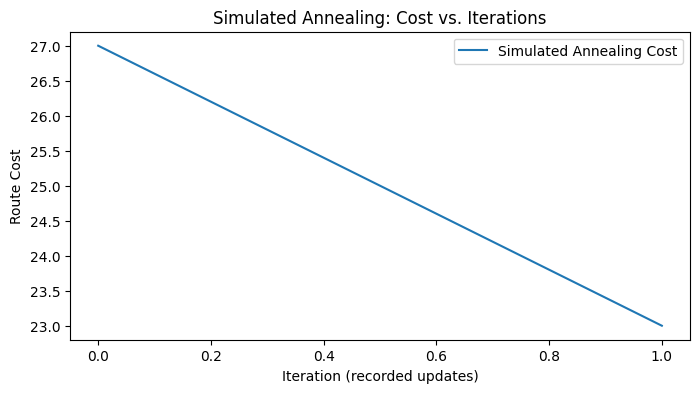

In [16]:
sa_start = time.time()
classic_path, classic_cost, sa_cost_history = simulated_annealing(custom_matrix)
sa_end = time.time()

print(f"Simulated Annealing Time: {sa_end - sa_start:.4f} seconds")
print(f"Simulated Annealing Solution: {classic_path}\n Cost: {classic_cost}")

plt.figure(figsize=(8, 4))
plt.plot(sa_cost_history, label='Simulated Annealing Cost')
plt.xlabel("Iteration (recorded updates)")
plt.ylabel("Route Cost")
plt.title("Simulated Annealing: Cost vs. Iterations")
plt.legend()
plt.show()

Initial candidate from Simulated Annealing:
Path: [3, 2, 0, 1] Cost: 23

Hybrid Iteration 1:
Quantum candidate (QAOA):
Path: [3, 2, 0, 1] Cost: 23.0
Refined candidate (Simulated Annealing):
Path: [3, 2, 0, 1] Cost: 23

Hybrid Iteration 2:
Quantum candidate (QAOA):
Path: [3, 2, 0, 1] Cost: 23.0
Refined candidate (Simulated Annealing):
Path: [3, 2, 0, 1] Cost: 23

Hybrid Iteration 3:
Quantum candidate (QAOA):
Path: [3, 2, 0, 1] Cost: 23.0
Refined candidate (Simulated Annealing):
Path: [3, 2, 0, 1] Cost: 23
Hybrid Solver Time: 819.0434 seconds
Hybrid Path: [3, 2, 0, 1]
Hybrid Cost: 23


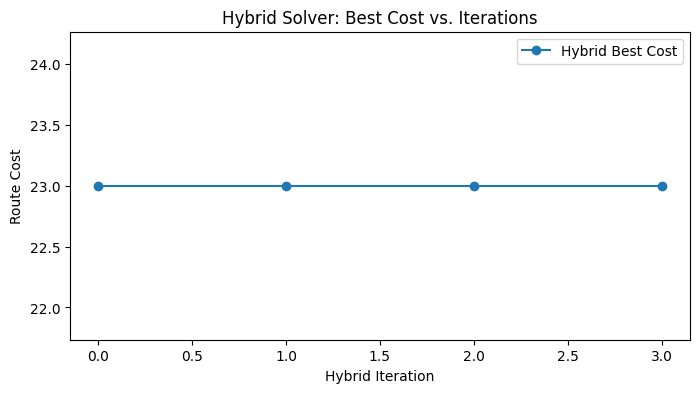

In [ ]:
start = time.time()
hybrid_path, hybrid_cost, hybrid_history = hybrid_solver(tsp_custom, qp, custom_matrix, iterations=3)
end = time.time()

print("--------------------------------------------------------")
print(f"Hybrid Solver Time: {end - start:.4f} seconds")
print("Hybrid Path:", hybrid_path)
print("Hybrid Cost:", hybrid_cost)

plt.figure(figsize=(8, 4))
plt.plot(hybrid_history, marker='o', label='Hybrid Best Cost')
plt.xlabel("Hybrid Iteration")
plt.ylabel("Route Cost")
plt.title("Hybrid Solver: Best Cost vs. Iterations")
plt.legend()
plt.show()


Visualizing Quantum Route:


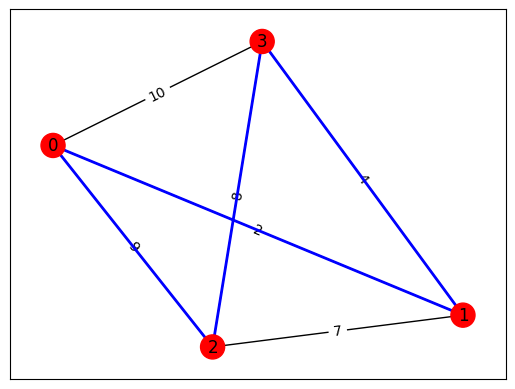


Visualizing Classical Route:


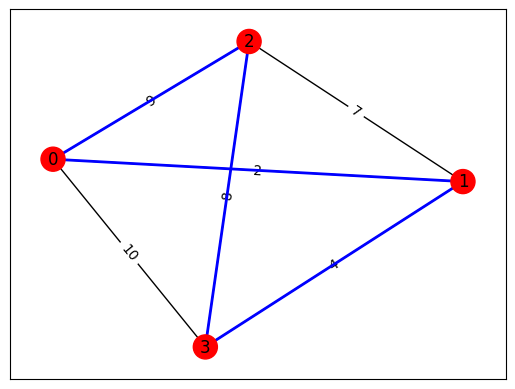


Visualizing Hybrid Route:


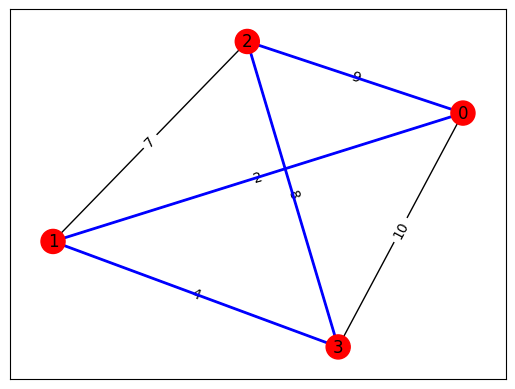

In [23]:
print("\nVisualizing Quantum Route:")
draw_graph(graph, path=path)

print("\nVisualizing Classical Route:")
draw_graph(graph, path=classic_path)

print("\nVisualizing Hybrid Route:")
draw_graph(graph, path=hybrid_path)

## For 4 complex Nodes

In [48]:
n_cities = 4
random_seed = 12

In [49]:
tsp = Tsp.create_random_instance(n_cities, seed=random_seed)
tsp_graph = tsp.graph
matrix = nx.to_numpy_array(tsp_graph)
print("Adjacency Matrix:\n", matrix)

Adjacency Matrix:
 [[ 0. 77. 72. 93.]
 [77.  0. 17. 49.]
 [72. 17.  0. 34.]
 [93. 49. 34.  0.]]


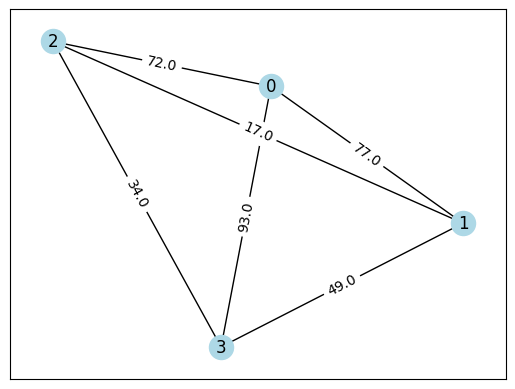

In [50]:
draw_graph(tsp_graph)

In [51]:
tsp_quadratic_program = tsp.to_quadratic_program()

In [52]:
obj_4, path_4 = tsp_solver(tsp, tsp_quadratic_program)
print(f"QAOA Solution for 4 cities: {path_4}\n Cost: {obj_4}")

QAOA Solution for 4 cities: [3, 2, 1, 0]
 Cost: 221.0


In [54]:
classic_path_, classic_cost_ = simulated_annealing(matrix)

print("Classical (Simulated Annealing) Solution:", classic_path_)
print("Classical Cost:", classic_cost_)

Classical (Simulated Annealing) Solution: [0, 1, 2, 3]
Classical Cost: 221.0



Visualizing Quantum Route:


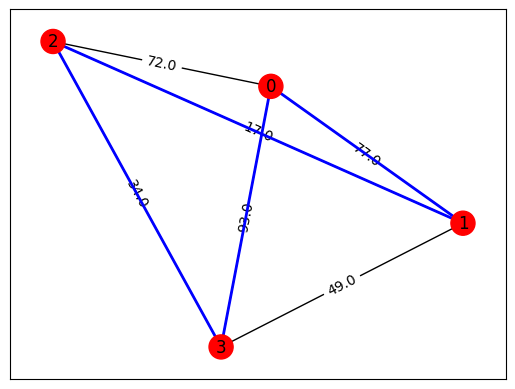


Visualizing Classical Route:


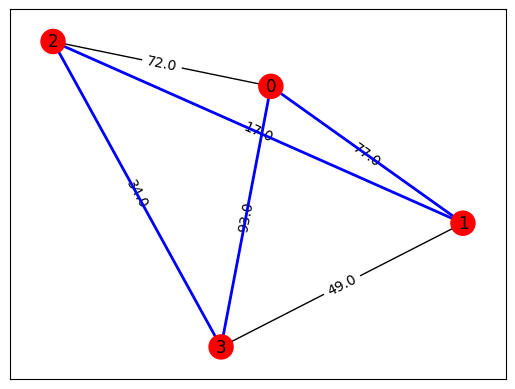

In [55]:
print("\nVisualizing Quantum Route:")
draw_graph(tsp_graph, path=path_4)

print("\nVisualizing Classical Route:")
draw_graph(tsp_graph, path=classic_path_)


## For another 4 nodes

In [57]:
matrix_ = np.array([[ 0, 48, 91, 33],
 [48. , 0. ,63. ,71.],
 [91. ,63. , 0., 92.],
 [33., 71., 92.,  0.]])

In [58]:
n_nodes_ = matrix_.shape[0]

In [60]:
G_custom_ = nx.complete_graph(n_nodes_)


In [61]:
for i, j in G_custom_.edges():
    G_custom_[i][j]['weight'] = matrix_[i][j]

In [62]:
tsp_custom_ = Tsp(G_custom_)

In [63]:
graph_ = tsp_custom_.graph

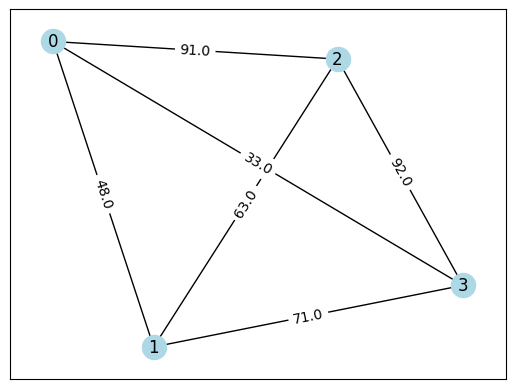

In [64]:
draw_graph(graph_)

In [65]:
qp_ = tsp_custom_.to_quadratic_program()

In [66]:
obj_1, path_1 = tsp_solver(tsp_custom_, qp_)
print(f"QAOA Solution: {path_1}\n Cost: {obj_1}")

QAOA Solution: [3, 2, 1, 0]
 Cost: 236.0


In [67]:
classic_path_1, classic_cost_1 = simulated_annealing(matrix_)

print("Classical (Simulated Annealing) Solution:", classic_path_1)
print("Classical Cost:", classic_cost_1)

Classical (Simulated Annealing) Solution: [0, 1, 2, 3]
Classical Cost: 236.0



Visualizing Quantum Route:


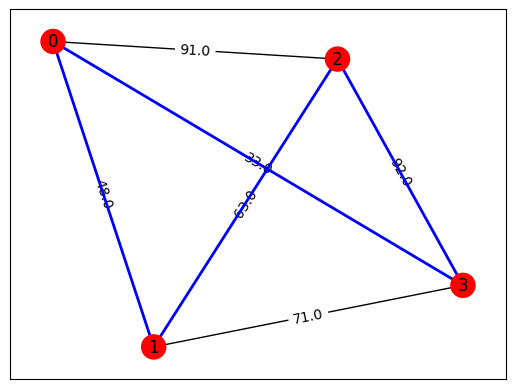


Visualizing Classical Route:


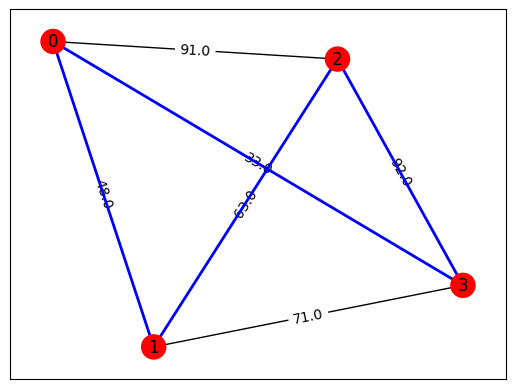

In [68]:
print("\nVisualizing Quantum Route:")
draw_graph(graph_, path=path_1)

print("\nVisualizing Classical Route:")
draw_graph(graph_, path=classic_path_1)


## QUBO Optimisation

In [16]:
print(qp.prettyprint())

Problem name: TSP

Minimize
  2*x_0_0*x_1_1 + 2*x_0_0*x_1_3 + 9*x_0_0*x_2_1 + 9*x_0_0*x_2_3 + 10*x_0_0*x_3_1
  + 10*x_0_0*x_3_3 + 2*x_0_1*x_1_0 + 2*x_0_1*x_1_2 + 9*x_0_1*x_2_0
  + 9*x_0_1*x_2_2 + 10*x_0_1*x_3_0 + 10*x_0_1*x_3_2 + 2*x_0_2*x_1_1
  + 2*x_0_2*x_1_3 + 9*x_0_2*x_2_1 + 9*x_0_2*x_2_3 + 10*x_0_2*x_3_1
  + 10*x_0_2*x_3_3 + 2*x_0_3*x_1_0 + 2*x_0_3*x_1_2 + 9*x_0_3*x_2_0
  + 9*x_0_3*x_2_2 + 10*x_0_3*x_3_0 + 10*x_0_3*x_3_2 + 6*x_1_0*x_2_1
  + 6*x_1_0*x_2_3 + 4*x_1_0*x_3_1 + 4*x_1_0*x_3_3 + 6*x_1_1*x_2_0
  + 6*x_1_1*x_2_2 + 4*x_1_1*x_3_0 + 4*x_1_1*x_3_2 + 6*x_1_2*x_2_1
  + 6*x_1_2*x_2_3 + 4*x_1_2*x_3_1 + 4*x_1_2*x_3_3 + 6*x_1_3*x_2_0
  + 6*x_1_3*x_2_2 + 4*x_1_3*x_3_0 + 4*x_1_3*x_3_2 + 8*x_2_0*x_3_1
  + 8*x_2_0*x_3_3 + 8*x_2_1*x_3_0 + 8*x_2_1*x_3_2 + 8*x_2_2*x_3_1
  + 8*x_2_2*x_3_3 + 8*x_2_3*x_3_0 + 8*x_2_3*x_3_2

Subject to
  Linear constraints (8)
    x_0_0 + x_0_1 + x_0_2 + x_0_3 == 1  'c0'
    x_1_0 + x_1_1 + x_1_2 + x_1_3 == 1  'c1'
    x_2_0 + x_2_1 + x_2_2 + x_2_3 == 1  'c2'
  

In [17]:
qubo = QuadraticProgramToQubo()
qubo_version = qubo.convert(qp)

In [18]:
print(qubo_version.prettyprint())

Problem name: TSP

Minimize
  626*x_0_0^2 + 626*x_0_0*x_0_1 + 626*x_0_0*x_0_2 + 626*x_0_0*x_0_3
  + 626*x_0_0*x_1_0 + 2*x_0_0*x_1_1 + 2*x_0_0*x_1_3 + 626*x_0_0*x_2_0
  + 9*x_0_0*x_2_1 + 9*x_0_0*x_2_3 + 626*x_0_0*x_3_0 + 10*x_0_0*x_3_1
  + 10*x_0_0*x_3_3 + 626*x_0_1^2 + 626*x_0_1*x_0_2 + 626*x_0_1*x_0_3
  + 2*x_0_1*x_1_0 + 626*x_0_1*x_1_1 + 2*x_0_1*x_1_2 + 9*x_0_1*x_2_0
  + 626*x_0_1*x_2_1 + 9*x_0_1*x_2_2 + 10*x_0_1*x_3_0 + 626*x_0_1*x_3_1
  + 10*x_0_1*x_3_2 + 626*x_0_2^2 + 626*x_0_2*x_0_3 + 2*x_0_2*x_1_1
  + 626*x_0_2*x_1_2 + 2*x_0_2*x_1_3 + 9*x_0_2*x_2_1 + 626*x_0_2*x_2_2
  + 9*x_0_2*x_2_3 + 10*x_0_2*x_3_1 + 626*x_0_2*x_3_2 + 10*x_0_2*x_3_3
  + 626*x_0_3^2 + 2*x_0_3*x_1_0 + 2*x_0_3*x_1_2 + 626*x_0_3*x_1_3
  + 9*x_0_3*x_2_0 + 9*x_0_3*x_2_2 + 626*x_0_3*x_2_3 + 10*x_0_3*x_3_0
  + 10*x_0_3*x_3_2 + 626*x_0_3*x_3_3 + 626*x_1_0^2 + 626*x_1_0*x_1_1
  + 626*x_1_0*x_1_2 + 626*x_1_0*x_1_3 + 626*x_1_0*x_2_0 + 6*x_1_0*x_2_1
  + 6*x_1_0*x_2_3 + 626*x_1_0*x_3_0 + 4*x_1_0*x_3_1 + 4*x_1_0*x_3_3
  + 62

In [20]:
op,offset=qubo_version.to_ising()
print(f"Offest : ",offset)
print("Ising Hamiltonian  : ")
print(op)

Offest :  5086.0
Ising Hamiltonian  : 
SparsePauliOp(['IIIIIIIIIIIIIIIZ', 'IIIIIIIIIIIIIIZI', 'IIIIIIIIIIIIIZII', 'IIIIIIIIIIIIZIII', 'IIIIIIIIIIIZIIII', 'IIIIIIIIIIZIIIII', 'IIIIIIIIIZIIIIII', 'IIIIIIIIZIIIIIII', 'IIIIIIIZIIIIIIII', 'IIIIIIZIIIIIIIII', 'IIIIIZIIIIIIIIII', 'IIIIZIIIIIIIIIII', 'IIIZIIIIIIIIIIII', 'IIZIIIIIIIIIIIII', 'IZIIIIIIIIIIIIII', 'ZIIIIIIIIIIIIIII', 'IIIIIIIIIIIIIIZZ', 'IIIIIIIIIIIIIZIZ', 'IIIIIIIIIIIIZIIZ', 'IIIIIIIIIIIZIIIZ', 'IIIIIIIIIIZIIIIZ', 'IIIIIIIIZIIIIIIZ', 'IIIIIIIZIIIIIIIZ', 'IIIIIIZIIIIIIIIZ', 'IIIIZIIIIIIIIIIZ', 'IIIZIIIIIIIIIIIZ', 'IIZIIIIIIIIIIIIZ', 'ZIIIIIIIIIIIIIIZ', 'IIIIIIIIIIIIIZZI', 'IIIIIIIIIIIIZIZI', 'IIIIIIIIIIIZIIZI', 'IIIIIIIIIIZIIIZI', 'IIIIIIIIIZIIIIZI', 'IIIIIIIZIIIIIIZI', 'IIIIIIZIIIIIIIZI', 'IIIIIZIIIIIIIIZI', 'IIIZIIIIIIIIIIZI', 'IIZIIIIIIIIIIIZI', 'IZIIIIIIIIIIIIZI', 'IIIIIIIIIIIIZZII', 'IIIIIIIIIIZIIZII', 'IIIIIIIIIZIIIZII', 'IIIIIIIIZIIIIZII', 'IIIIIIZIIIIIIZII', 'IIIIIZIIIIIIIZII', 'IIIIZIIIIIIIIZII', 'IIZIIIIIIIIIIZII', 'IZIII

In [21]:
qa=MinimumEigenOptimizer(QAOA(sampler=Sampler(),optimizer=COBYLA()))
rslt=qa.solve(qubo_version)
print(rslt.prettyprint())

objective function value: 23.0
variable values: x_0_0=0.0, x_0_1=0.0, x_0_2=1.0, x_0_3=0.0, x_1_0=0.0, x_1_1=0.0, x_1_2=0.0, x_1_3=1.0, x_2_0=0.0, x_2_1=1.0, x_2_2=0.0, x_2_3=0.0, x_3_0=1.0, x_3_1=0.0, x_3_2=0.0, x_3_3=0.0
status: SUCCESS


In [23]:
qubo_path = tsp_custom.interpret(rslt.x)
print("QAOA Solution: ",qubo_path)
print("Cost: ",rslt.fval+offset)

QAOA Solution:  [3, 2, 0, 1]
Cost:  5109.0


## SPSA Optimiser

In [26]:
print(qp.prettyprint())

Problem name: TSP

Minimize
  2*x_0_0*x_1_1 + 2*x_0_0*x_1_3 + 9*x_0_0*x_2_1 + 9*x_0_0*x_2_3 + 10*x_0_0*x_3_1
  + 10*x_0_0*x_3_3 + 2*x_0_1*x_1_0 + 2*x_0_1*x_1_2 + 9*x_0_1*x_2_0
  + 9*x_0_1*x_2_2 + 10*x_0_1*x_3_0 + 10*x_0_1*x_3_2 + 2*x_0_2*x_1_1
  + 2*x_0_2*x_1_3 + 9*x_0_2*x_2_1 + 9*x_0_2*x_2_3 + 10*x_0_2*x_3_1
  + 10*x_0_2*x_3_3 + 2*x_0_3*x_1_0 + 2*x_0_3*x_1_2 + 9*x_0_3*x_2_0
  + 9*x_0_3*x_2_2 + 10*x_0_3*x_3_0 + 10*x_0_3*x_3_2 + 6*x_1_0*x_2_1
  + 6*x_1_0*x_2_3 + 4*x_1_0*x_3_1 + 4*x_1_0*x_3_3 + 6*x_1_1*x_2_0
  + 6*x_1_1*x_2_2 + 4*x_1_1*x_3_0 + 4*x_1_1*x_3_2 + 6*x_1_2*x_2_1
  + 6*x_1_2*x_2_3 + 4*x_1_2*x_3_1 + 4*x_1_2*x_3_3 + 6*x_1_3*x_2_0
  + 6*x_1_3*x_2_2 + 4*x_1_3*x_3_0 + 4*x_1_3*x_3_2 + 8*x_2_0*x_3_1
  + 8*x_2_0*x_3_3 + 8*x_2_1*x_3_0 + 8*x_2_1*x_3_2 + 8*x_2_2*x_3_1
  + 8*x_2_2*x_3_3 + 8*x_2_3*x_3_0 + 8*x_2_3*x_3_2

Subject to
  Linear constraints (8)
    x_0_0 + x_0_1 + x_0_2 + x_0_3 == 1  'c0'
    x_1_0 + x_1_1 + x_1_2 + x_1_3 == 1  'c1'
    x_2_0 + x_2_1 + x_2_2 + x_2_3 == 1  'c2'
  

In [ ]:
qaoa_spsa = MinimumEigenOptimizer(QAOA(sampler=Sampler(), optimizer=SPSA(), reps=3))    

In [28]:
qubo_path_spsa = tsp_custom.interpret(qaoa_spsa.solve(qp).x)
print("QAOA Solution with SPSA: ", qubo_path_spsa)

QAOA Solution with COBYLA:  [3, 2, 0, 1]


### QAOA Circuit Diagram



In [44]:
qc.decompose().draw('mpl')



In [45]:
qc.decompose().decompose().draw('mpl')